In [1]:
# Loading the cleaned retail sales dataset from the processed data folder for product performance analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/cleaned_data.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (100000, 28)


,Customer ID,Customer Name,Last Name,Date of Birth,Sales,Year,Outlet Type,City Type,Category of Goods,Region,...,Postal Code,Product ID,Sub-Category,Product Name,Quantity,Discount,Profit,Month,Quarter,Year-Month
0,CUST000001,Curtis,Krause,1973-11-29,3344.69,2020,Large,Tier 1,Fast Food,East,...,700001,PROD000001,Burgers,Burgers - 718,3,0.09,448.24,4,2,2020-04
1,CUST000002,Jeremy,Foster,1987-08-30,37094.41,2021,Medium,Tier 2,Fast Food,East,...,160001,PROD000002,Pizzas,Pizzas - 519,5,0.39,3134.34,1,1,2021-01
2,CUST000003,Ariel,Mccann,1980-12-15,35501.08,2020,Large,Village,Electric Appliances,South,...,380001,PROD000003,Fans,Fans - 395,6,0.07,8324.21,8,3,2020-08
3,CUST000004,Colleen,Maynard,1989-05-23,8969.33,2021,Medium,Village,Dairy Products,East,...,700001,PROD000004,Milk,Milk - 798,4,0.18,1962.66,10,4,2021-10
4,CUST000005,Gina,Holden,1957-12-31,35530.44,2019,Small,Village,Sessional Fruits & Vegetables,West,...,110001,PROD000005,Tomatoes,Tomatoes - 442,4,0.27,2843.93,1,1,2019-01


In [2]:
# Checking product and sub-category uniqueness to determine the appropriate level for product performance analysis

print("Unique Product IDs:", df["Product ID"].nunique())
print("Unique Product Names:", df["Product Name"].nunique())
print("Unique Sub-Categories:", df["Sub-Category"].nunique())

print("\nTransactions per Product Name:")
product_transaction_counts = (
    df.groupby("Product Name")
    .size()
    .reset_index(name="Transaction_Count")
)

display(
    product_transaction_counts["Transaction_Count"].describe()
)

Unique Product IDs: 100000
Unique Product Names: 21365
Unique Sub-Categories: 24

Transactions per Product Name:


count    21365.000000
mean         4.680552
std          2.084087
min          1.000000
25%          3.000000
50%          4.000000
75%          6.000000
max         15.000000
Name: Transaction_Count, dtype: float64

In [3]:
'''
Product IDs: 100,000 → unique per transaction, so we won't use them for aggregation.
Product Names: 21,365 → suitable for product-level performance analysis.
Sub-Categories: 24 → suitable for broader product-category analysis.
Each product name appears 1–15 times, so unlike Customer ID, Product Name provides meaningful aggregation.
'''

"\nProduct IDs: 100,000 → unique per transaction, so we won't use them for aggregation.\nProduct Names: 21,365 → suitable for product-level performance analysis.\nSub-Categories: 24 → suitable for broader product-category analysis.\nEach product name appears 1–15 times, so unlike Customer ID, Product Name provides meaningful aggregation.\n"

In [4]:
# Aggregating sales, profit, quantity, discount, and transaction count for each product name

product_performance = (
    df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Average_Discount=("Discount", "mean"),
        Transaction_Count=("Order ID", "nunique")
    )
    .reset_index()
)

product_performance["Profit_Margin"] = (
    product_performance["Total_Profit"]
    / product_performance["Total_Sales"]
    * 100
)

print("Product Performance Shape:", product_performance.shape)

display(
    product_performance.head(10)
)

Product Performance Shape: (21365, 7)


,Product Name,Total_Sales,Total_Profit,Total_Quantity,Average_Discount,Transaction_Count,Profit_Margin
0,Apples - 100,138658.02,12503.05,38,0.302000,5,9.017185
1,Apples - 102,183266.27,19193.44,20,0.214000,5,10.472980
2,Apples - 103,97242.51,12167.92,19,0.310000,4,12.512964
3,Apples - 104,248233.35,32539.75,40,0.301429,7,13.108533
4,Apples - 105,108641.95,16794.52,15,0.287500,4,15.458596
5,Apples - 106,85698.11,10028.86,17,0.216667,3,11.702545
6,Apples - 107,3529.11,439.65,6,0.260000,1,12.457815
7,Apples - 108,105878.75,17523.21,22,0.190000,4,16.550262
8,Apples - 109,208256.28,31150.94,40,0.307143,7,14.957983
9,Apples - 110,206965.22,33777.67,38,0.320000,6,16.320457


In [5]:
# Identifying the top 10 product names based on their total sales revenue

top_products_sales = (
    product_performance
    .sort_values("Total_Sales", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(
    top_products_sales[
        [
            "Product Name",
            "Total_Sales",
            "Total_Profit",
            "Total_Quantity",
            "Transaction_Count",
            "Profit_Margin"
        ]
    ].style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Profit_Margin": "{:.2f}%"
    })
)

,Product Name,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count,Profit_Margin
0,Beds - 120,"₹467,564.82","₹77,643.63",66,14,16.61%
1,Refrigerators - 338,"₹463,807.16","₹66,765.54",64,13,14.40%
2,Butter - 951,"₹458,374.84","₹67,379.88",76,14,14.70%
3,Mops - 693,"₹418,713.15","₹58,531.96",87,13,13.98%
4,Burgers - 729,"₹408,224.56","₹59,266.34",64,14,14.52%
5,Fans - 611,"₹402,263.31","₹60,258.06",64,12,14.98%
6,Mangoes - 912,"₹402,158.97","₹70,078.99",57,12,17.43%
7,Apples - 425,"₹379,721.59","₹65,969.62",69,14,17.37%
8,Milk - 660,"₹373,800.17","₹49,179.78",63,11,13.16%
9,Refrigerators - 709,"₹373,166.48","₹63,501.42",50,12,17.02%


In [6]:
# Identifying the top 10 product names based on their total profit generated

top_products_profit = (
    product_performance
    .sort_values("Total_Profit", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(
    top_products_profit[
        [
            "Product Name",
            "Total_Sales",
            "Total_Profit",
            "Total_Quantity",
            "Transaction_Count",
            "Profit_Margin"
        ]
    ].style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Profit_Margin": "{:.2f}%"
    })
)

,Product Name,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count,Profit_Margin
0,Beds - 120,"₹467,564.82","₹77,643.63",66,14,16.61%
1,Mangoes - 912,"₹402,158.97","₹70,078.99",57,12,17.43%
2,Refrigerators - 538,"₹353,767.23","₹67,496.63",69,11,19.08%
3,Butter - 951,"₹458,374.84","₹67,379.88",76,14,14.70%
4,Refrigerators - 338,"₹463,807.16","₹66,765.54",64,13,14.40%
5,Microwaves - 157,"₹362,578.77","₹66,256.98",79,12,18.27%
6,Apples - 425,"₹379,721.59","₹65,969.62",69,14,17.37%
7,Microwaves - 808,"₹352,721.83","₹63,624.38",68,10,18.04%
8,Refrigerators - 709,"₹373,166.48","₹63,501.42",50,12,17.02%
9,Mops - 847,"₹368,502.08","₹62,670.68",54,13,17.01%


In [7]:
'''
Interesting result: Beds - 120 is the highest-profit product as well as the highest-sales product. 
However, some products have higher profit margins despite lower total sales—for example, Refrigerators - 538 has a 19.08% margin.
'''

'\nInteresting result: Beds - 120 is the highest-profit product as well as the highest-sales product. \nHowever, some products have higher profit margins despite lower total sales—for example, Refrigerators - 538 has a 19.08% margin.\n'

In [8]:
# Identifying the 10 product names with the lowest total sales for low-performance analysis

lowest_products_sales = (
    product_performance
    .sort_values("Total_Sales", ascending=True)
    .head(10)
    .reset_index(drop=True)
)

display(
    lowest_products_sales[
        [
            "Product Name",
            "Total_Sales",
            "Total_Profit",
            "Total_Quantity",
            "Average_Discount",
            "Transaction_Count",
            "Profit_Margin"
        ]
    ].style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Average_Discount": "{:.2%}",
        "Profit_Margin": "{:.2f}%"
    })
)

,Product Name,Total_Sales,Total_Profit,Total_Quantity,Average_Discount,Transaction_Count,Profit_Margin
0,Cheese - 665,₹121.20,₹9.93,3,24.00%,1,8.19%
1,Washing Machines - 290,₹302.84,₹21.50,9,49.00%,1,7.10%
2,Fans - 426,₹409.15,₹36.18,5,36.00%,1,8.84%
3,Sofas - 378,₹520.15,₹70.97,6,38.00%,1,13.64%
4,Beds - 965,₹573.56,₹116.19,6,27.00%,1,20.26%
5,Mops - 309,₹609.47,₹47.38,9,35.00%,1,7.77%
6,Fans - 766,₹628.47,₹81.50,1,38.00%,1,12.97%
7,Microwaves - 365,₹707.03,₹105.52,1,34.00%,1,14.92%
8,Butter - 669,₹761.94,₹129.77,10,31.00%,1,17.03%
9,Refrigerators - 550,₹813.42,₹48.96,2,42.00%,1,6.02%


In [9]:
'''
The lowest-sales products are identified. 
One important interpretation point: these products each have only 1 transaction, 
so their low sales may simply reflect low transaction frequency rather than genuinely poor product demand. 
We should mention this limitation in the report rather than labeling them as definitively poor-performing.
'''

'\nThe lowest-sales products are identified. \nOne important interpretation point: these products each have only 1 transaction, \nso their low sales may simply reflect low transaction frequency rather than genuinely poor product demand. \nWe should mention this limitation in the report rather than labeling them as definitively poor-performing.\n'

In [10]:
# Identifying products with relatively high sales but lower profit margins to examine potentially less profitable products

sales_profit_analysis = product_performance.copy()

sales_threshold = sales_profit_analysis["Total_Sales"].quantile(0.75)
margin_threshold = sales_profit_analysis["Profit_Margin"].quantile(0.25)

high_sales_low_margin = (
    sales_profit_analysis[
        (sales_profit_analysis["Total_Sales"] >= sales_threshold) &
        (sales_profit_analysis["Profit_Margin"] <= margin_threshold)
    ]
    .sort_values(
        ["Total_Sales", "Profit_Margin"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("75th Percentile Sales Threshold:", f"₹{sales_threshold:,.2f}")
print("25th Percentile Profit Margin Threshold:", f"{margin_threshold:.2f}%")
print("Products Meeting High-Sales/Low-Margin Criteria:", len(high_sales_low_margin))

display(
    high_sales_low_margin[
        [
            "Product Name",
            "Total_Sales",
            "Total_Profit",
            "Average_Discount",
            "Transaction_Count",
            "Profit_Margin"
        ]
    ].head(10).style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Average_Discount": "{:.2%}",
        "Profit_Margin": "{:.2f}%"
    })
)

75th Percentile Sales Threshold: ₹154,837.14
25th Percentile Profit Margin Threshold: 12.90%
Products Meeting High-Sales/Low-Margin Criteria: 976


,Product Name,Total_Sales,Total_Profit,Average_Discount,Transaction_Count,Profit_Margin
0,Tables - 664,"₹355,396.01","₹38,291.03",38.25%,12,10.77%
1,Tables - 722,"₹352,271.17","₹45,277.33",25.22%,9,12.85%
2,Tables - 772,"₹347,970.45","₹42,616.88",35.20%,10,12.25%
3,Washing Machines - 697,"₹338,861.83","₹42,640.91",23.67%,12,12.58%
4,Fries - 944,"₹323,548.67","₹40,523.41",35.38%,8,12.52%
5,Cheese - 379,"₹320,607.93","₹38,664.33",26.30%,10,12.06%
6,Cheese - 731,"₹318,054.66","₹40,282.58",31.55%,11,12.67%
7,Carrots - 219,"₹317,309.71","₹40,263.85",33.18%,11,12.69%
8,Cheese - 536,"₹316,085.26","₹40,601.41",34.90%,10,12.85%
9,Apples - 710,"₹315,213.60","₹40,233.81",31.00%,11,12.76%


In [11]:
'''
This gives us an important product-performance insight:

976 products fall into the high-sales/low-margin group.
The sales threshold is ₹154,837.14.
The low-margin threshold is 12.90%.
Several products have substantial sales but relatively low margins, suggesting that revenue alone should not be used to judge product performance.
Discount levels are also useful to investigate because some of these products have relatively high average discounts.
'''

'\nThis gives us an important product-performance insight:\n\n976 products fall into the high-sales/low-margin group.\nThe sales threshold is ₹154,837.14.\nThe low-margin threshold is 12.90%.\nSeveral products have substantial sales but relatively low margins, suggesting that revenue alone should not be used to judge product performance.\nDiscount levels are also useful to investigate because some of these products have relatively high average discounts.\n'

In [12]:
# Analyzing the relationship between average discount and profit margin across products

discount_margin_analysis = product_performance[
    [
        "Product Name",
        "Average_Discount",
        "Profit_Margin",
        "Total_Sales",
        "Total_Profit"
    ]
].copy()

print("Correlation between Average Discount and Profit Margin:")

discount_margin_correlation = (
    discount_margin_analysis[
        ["Average_Discount", "Profit_Margin"]
    ]
    .corr()
    .loc["Average_Discount", "Profit_Margin"]
)

print(f"{discount_margin_correlation:.4f}")

display(
    discount_margin_analysis.describe()
)

Correlation between Average Discount and Profit Margin:
-0.4873


,Average_Discount,Profit_Margin,Total_Sales,Total_Profit
count,21365.000000,21365.000000,21365.000000,21365.000000
mean,0.251199,14.974419,117408.893713,17576.902009
std,0.076596,3.080211,60922.719682,9668.833956
min,0.000000,5.402490,121.200000,9.930000
25%,0.202500,12.895395,72679.390000,10427.770000
50%,0.251667,14.819558,110638.020000,16385.200000
75%,0.300000,16.858742,154837.140000,23417.400000
max,0.500000,29.557957,467564.820000,77643.630000


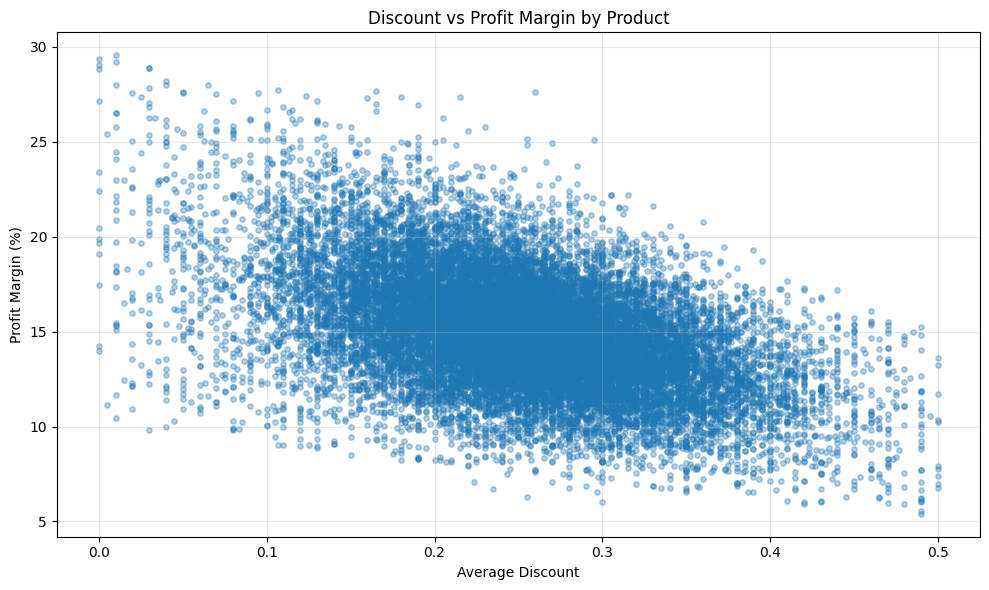

In [13]:
# Visualizing the relationship between average product discount and profit margin using a scatter plot

plt.figure(figsize=(10, 6))

plt.scatter(
    product_performance["Average_Discount"],
    product_performance["Profit_Margin"],
    alpha=0.35,
    s=15
)

plt.title("Discount vs Profit Margin by Product")
plt.xlabel("Average Discount")
plt.ylabel("Profit Margin (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
# Aggregating sales, profit, quantity, discount, and transaction count for each sub-category

subcategory_performance = (
    df.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Average_Discount=("Discount", "mean"),
        Transaction_Count=("Order ID", "nunique")
    )
    .reset_index()
)

subcategory_performance["Profit_Margin"] = (
    subcategory_performance["Total_Profit"]
    / subcategory_performance["Total_Sales"]
    * 100
)

subcategory_performance = subcategory_performance.sort_values(
    "Total_Sales",
    ascending=False
)

print("Sub-Category Performance Shape:", subcategory_performance.shape)

display(subcategory_performance)

Sub-Category Performance Shape: (24, 7)


,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Average_Discount,Transaction_Count,Profit_Margin
14,Mops,1.095685e+08,16395505.04,24191,0.252147,4397,14.963699
5,Carrots,1.075179e+08,16136518.89,23231,0.247450,4232,15.008210
13,Milk,1.058201e+08,15782966.79,23081,0.252579,4222,14.914902
12,Microwaves,1.058080e+08,16083504.84,23337,0.247410,4217,15.200658
15,Pizzas,1.057033e+08,15817570.33,23394,0.254281,4240,14.964115
18,Sofas,1.055018e+08,15787824.47,22970,0.251683,4184,14.964506
3,Burgers,1.053565e+08,15829860.41,22851,0.252641,4158,15.025041
7,Cheese,1.053360e+08,15770492.08,22705,0.252875,4146,14.971608
16,Refrigerators,1.051124e+08,15650138.81,23147,0.251916,4164,14.888957
22,Washing Machines,1.049020e+08,15564814.67,22944,0.253703,4170,14.837484


In [15]:
'''
Key observations:

Mops has the highest sales: about ₹109.57M.
Chairs has the lowest sales: about ₹99.50M.
Microwaves has the highest profit margin: 15.20%.
Tables has the lowest profit margin: 14.83%.
Overall, the sub-category margins are fairly close to each other, around 14.8%–15.2%.
'''

'\nKey observations:\n\nMops has the highest sales: about ₹109.57M.\nChairs has the lowest sales: about ₹99.50M.\nMicrowaves has the highest profit margin: 15.20%.\nTables has the lowest profit margin: 14.83%.\nOverall, the sub-category margins are fairly close to each other, around 14.8%–15.2%.\n'

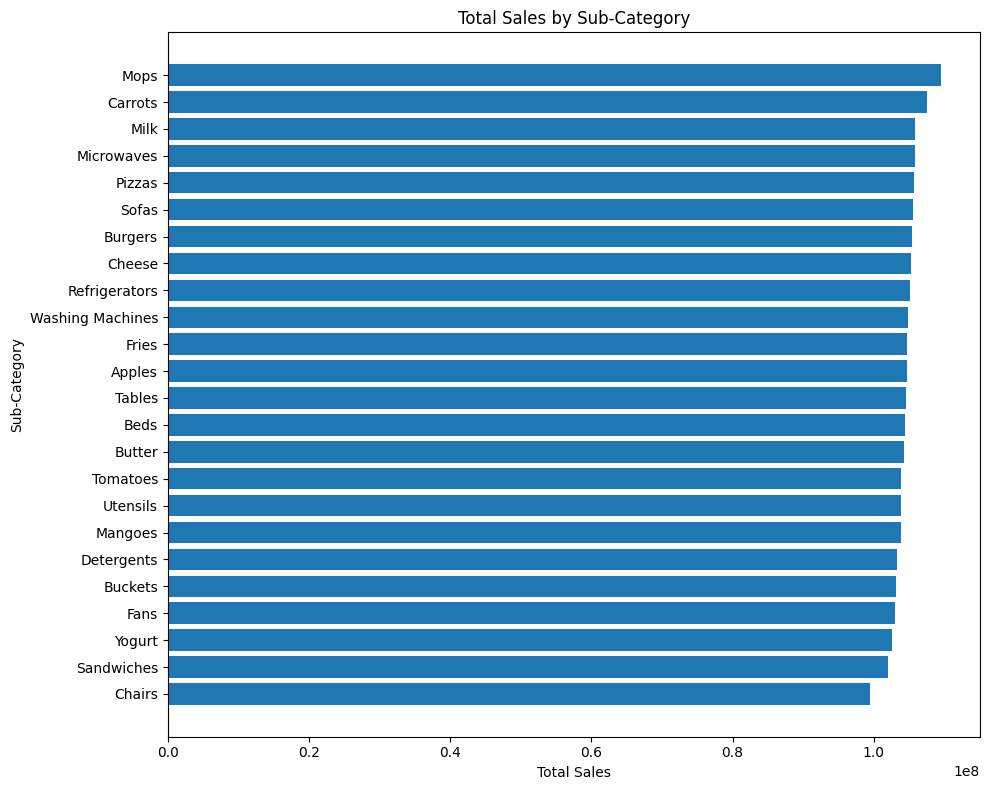

In [16]:
# Visualizing total sales across all sub-categories to compare their sales performance

plt.figure(figsize=(10, 8))

subcategory_sales_plot = subcategory_performance.sort_values(
    "Total_Sales",
    ascending=True
)

plt.barh(
    subcategory_sales_plot["Sub-Category"],
    subcategory_sales_plot["Total_Sales"]
)

plt.title("Total Sales by Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

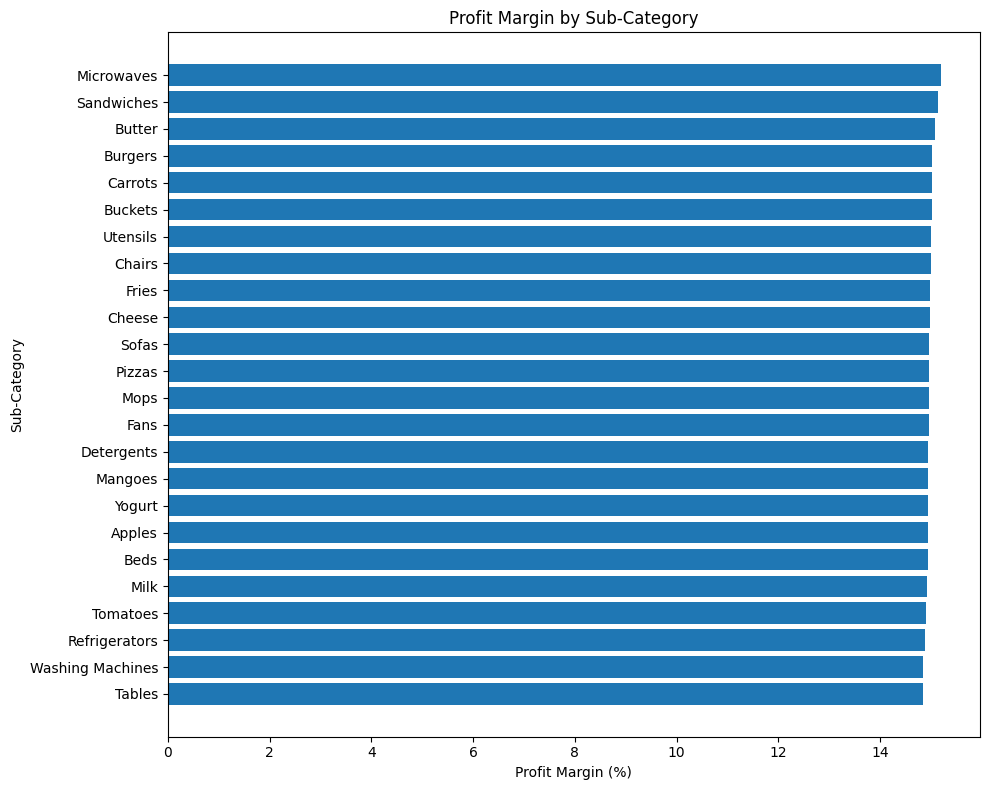

In [17]:
# Visualizing profit margins across all sub-categories to compare profitability

plt.figure(figsize=(10, 8))

subcategory_margin_plot = subcategory_performance.sort_values(
    "Profit_Margin",
    ascending=True
)

plt.barh(
    subcategory_margin_plot["Sub-Category"],
    subcategory_margin_plot["Profit_Margin"]
)

plt.title("Profit Margin by Sub-Category")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

In [19]:
# Classifying products into four performance groups based on median sales and profit

sales_median = product_performance["Total_Sales"].median()
profit_median = product_performance["Total_Profit"].median()

product_performance["Performance_Group"] = np.select(
    [
        (product_performance["Total_Sales"] >= sales_median) &
        (product_performance["Total_Profit"] >= profit_median),

        (product_performance["Total_Sales"] >= sales_median) &
        (product_performance["Total_Profit"] < profit_median),

        (product_performance["Total_Sales"] < sales_median) &
        (product_performance["Total_Profit"] >= profit_median),

        (product_performance["Total_Sales"] < sales_median) &
        (product_performance["Total_Profit"] < profit_median)
    ],
    [
        "High Sales - High Profit",
        "High Sales - Low Profit",
        "Low Sales - High Profit",
        "Low Sales - Low Profit"
    ],
    default="Unclassified"
)

print(f"Sales Median: ₹{sales_median:,.2f}")
print(f"Profit Median: ₹{profit_median:,.2f}")

print("\nPerformance Group Distribution:")

display(
    product_performance["Performance_Group"]
    .value_counts()
    .to_frame("Product_Count")
)

display(
    product_performance[
        [
            "Product Name",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin",
            "Performance_Group"
        ]
    ]
    .sort_values(
        ["Performance_Group", "Total_Sales"],
        ascending=[True, False]
    )
    .head(20)
)

Sales Median: ₹110,638.02
Profit Median: ₹16,385.20

Performance Group Distribution:


,Product_Count
Performance_Group,
High Sales - High Profit,9540
Low Sales - Low Profit,9539
High Sales - Low Profit,1143
Low Sales - High Profit,1143


,Product Name,Total_Sales,Total_Profit,Profit_Margin,Performance_Group
904,Beds - 120,467564.82,77643.63,16.605961,High Sales - High Profit
14468,Refrigerators - 338,463807.16,66765.54,14.395108,High Sales - High Profit
4389,Butter - 951,458374.84,67379.88,14.699734,High Sales - High Profit
13038,Mops - 693,418713.15,58531.96,13.979012,High Sales - High Profit
3285,Burgers - 729,408224.56,59266.34,14.518073,High Sales - High Profit
8512,Fans - 611,402263.31,60258.06,14.979755,High Sales - High Profit
10590,Mangoes - 912,402158.97,70078.99,17.425694,High Sales - High Profit
318,Apples - 425,379721.59,65969.62,17.373155,High Sales - High Profit
12120,Milk - 660,373800.17,49179.78,13.156703,High Sales - High Profit
14836,Refrigerators - 709,373166.48,63501.42,17.016914,High Sales - High Profit


In [20]:
'''
The two smaller groups are particularly useful for business analysis:

High Sales – Low Profit: products generating revenue but with relatively lower profit.
Low Sales – High Profit: products with good profitability but lower sales volume.
'''

'\nThe two smaller groups are particularly useful for business analysis:\n\nHigh Sales – Low Profit: products generating revenue but with relatively lower profit.\nLow Sales – High Profit: products with good profitability but lower sales volume.\n'

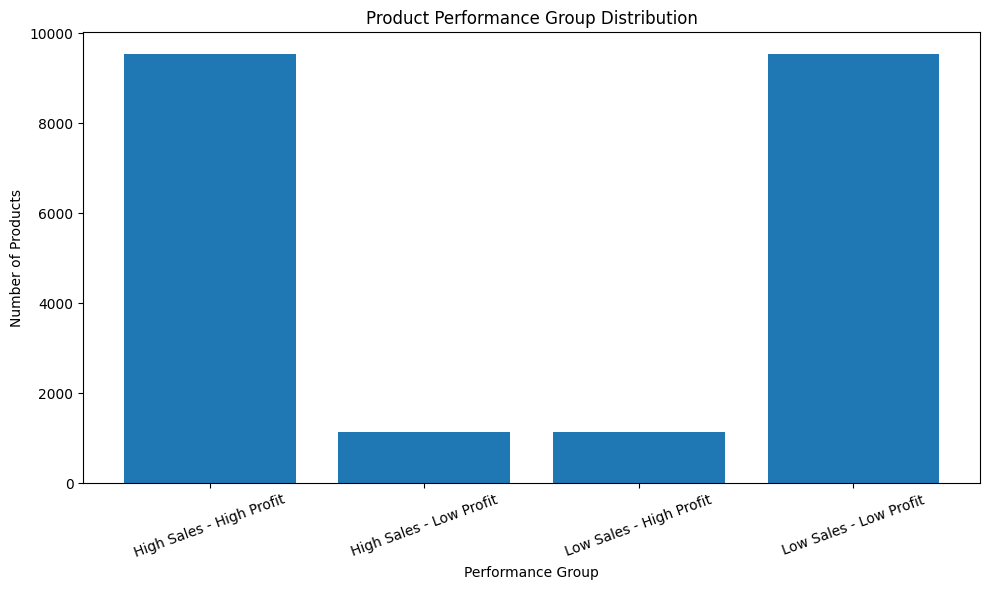

In [21]:
# Visualizing the distribution of products across the four sales-profit performance groups

performance_group_counts = (
    product_performance["Performance_Group"]
    .value_counts()
    .reindex([
        "High Sales - High Profit",
        "High Sales - Low Profit",
        "Low Sales - High Profit",
        "Low Sales - Low Profit"
    ])
)

plt.figure(figsize=(10, 6))

plt.bar(
    performance_group_counts.index,
    performance_group_counts.values
)

plt.title("Product Performance Group Distribution")
plt.xlabel("Performance Group")
plt.ylabel("Number of Products")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [22]:
# Identifying products with high sales but comparatively low profit for profitability review

high_sales_low_profit = product_performance[
    product_performance["Performance_Group"] == "High Sales - Low Profit"
].copy()

high_sales_low_profit = high_sales_low_profit.sort_values(
    "Total_Sales",
    ascending=False
)

print("High Sales - Low Profit Products:", len(high_sales_low_profit))

display(
    high_sales_low_profit[
        [
            "Product Name",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin",
            "Average_Discount",
            "Transaction_Count"
        ]
    ].head(15)
)

High Sales - Low Profit Products: 1143


,Product Name,Total_Sales,Total_Profit,Profit_Margin,Average_Discount,Transaction_Count
9825,Mangoes - 137,179766.52,16380.69,9.112203,0.324000,5
3268,Burgers - 712,176335.08,13324.73,7.556483,0.438000,5
5287,Carrots - 954,173047.91,15543.10,8.981963,0.270000,7
1252,Beds - 473,171715.12,15661.91,9.120868,0.416000,5
16401,Sofas - 489,169340.81,13738.16,8.112728,0.300000,5
7402,Detergents - 391,166276.03,15083.78,9.071530,0.325000,4
16,Apples - 117,164498.44,14777.06,8.983100,0.280000,4
12213,Milk - 755,164417.45,15587.46,9.480417,0.438333,6
6146,Chairs - 920,164409.33,15379.59,9.354451,0.396667,6
17167,Tables - 359,163705.33,15244.02,9.311865,0.386000,5


In [23]:
'''
This output gives us a useful business insight: several high-sales/low-profit products have relatively high discounts. 
For example, Burgers - 712 has a 43.8% average discount and only a 7.56% profit margin. 
'''

'\nThis output gives us a useful business insight: several high-sales/low-profit products have relatively high discounts. \nFor example, Burgers - 712 has a 43.8% average discount and only a 7.56% profit margin. \n'

In [24]:
# Identifying products with low sales but comparatively high profit for growth opportunity analysis

low_sales_high_profit = product_performance[
    product_performance["Performance_Group"] == "Low Sales - High Profit"
].copy()

low_sales_high_profit = low_sales_high_profit.sort_values(
    "Total_Profit",
    ascending=False
)

print("Low Sales - High Profit Products:", len(low_sales_high_profit))

display(
    low_sales_high_profit[
        [
            "Product Name",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin",
            "Average_Discount",
            "Transaction_Count"
        ]
    ].head(15)
)

Low Sales - High Profit Products: 1143


,Product Name,Total_Sales,Total_Profit,Profit_Margin,Average_Discount,Transaction_Count
16236,Sofas - 321,108700.71,28554.01,26.268467,0.033333,3
9963,Mangoes - 276,110238.49,26064.23,23.643493,0.228333,6
15859,Sandwiches - 842,108716.56,25308.50,23.279342,0.113333,3
6593,Cheese - 474,103580.81,25167.68,24.297628,0.112000,5
7428,Detergents - 417,105581.16,25022.33,23.699616,0.170000,3
923,Beds - 139,103930.02,24684.41,23.750991,0.148333,6
3918,Butter - 472,110488.76,24584.14,22.250354,0.172500,4
12709,Mops - 359,104700.11,24303.79,23.212765,0.090000,4
16694,Sofas - 783,93218.90,24081.61,25.833399,0.143333,3
15564,Sandwiches - 543,105676.03,23997.21,22.708281,0.173333,3


In [25]:
'''
1,143 Low Sales – High Profit products
These products have relatively strong profit despite lower sales.
For example, Sofas - 321 has about ₹108.7K sales and ₹28.6K profit, giving a 26.27% margin.
These products can be considered potential candidates for increased promotion or sales expansion.
'''

'\n1,143 Low Sales – High Profit products\nThese products have relatively strong profit despite lower sales.\nFor example, Sofas - 321 has about ₹108.7K sales and ₹28.6K profit, giving a 26.27% margin.\nThese products can be considered potential candidates for increased promotion or sales expansion.\n'

In [26]:
# Saving the complete product performance analysis with performance groups to the processed data folder

product_performance.to_csv(
    "../data/processed/product_performance.csv",
    index=False
)

print("Product performance analysis saved successfully.")
print("File: ../data/processed/product_performance.csv")
print("Rows:", len(product_performance))
print("Columns:", len(product_performance.columns))

Product performance analysis saved successfully.
File: ../data/processed/product_performance.csv
Rows: 21365
Columns: 8


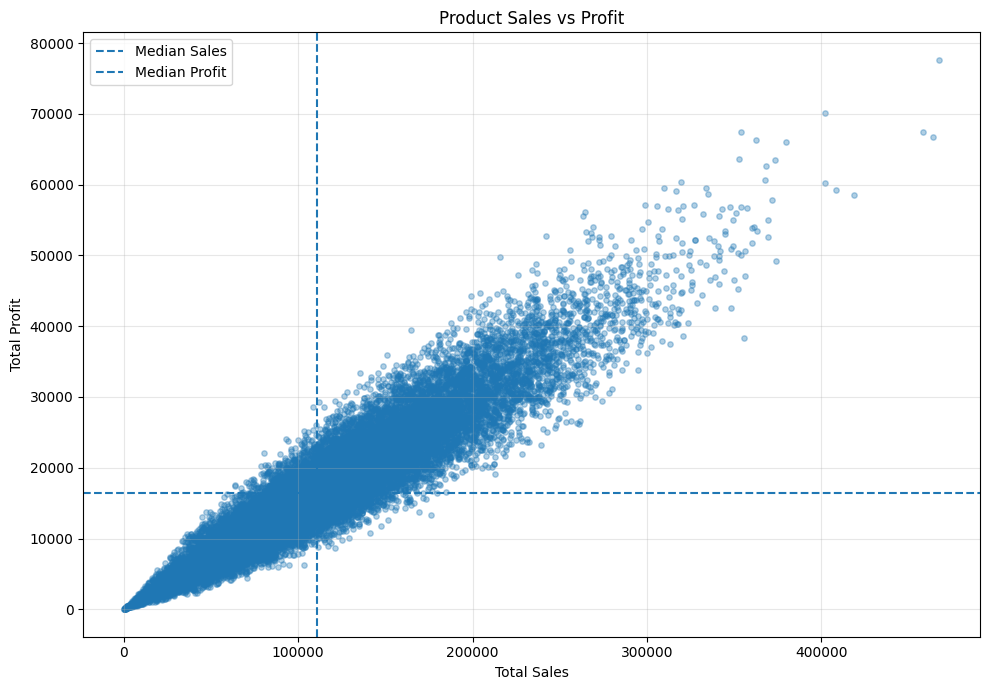

In [27]:
# Visualizing the relationship between total sales and total profit across products

plt.figure(figsize=(10, 7))

plt.scatter(
    product_performance["Total_Sales"],
    product_performance["Total_Profit"],
    alpha=0.35,
    s=15
)

plt.axvline(
    product_performance["Total_Sales"].median(),
    linestyle="--",
    linewidth=1.5,
    label="Median Sales"
)

plt.axhline(
    product_performance["Total_Profit"].median(),
    linestyle="--",
    linewidth=1.5,
    label="Median Profit"
)

plt.title("Product Sales vs Profit")
plt.xlabel("Total Sales")
plt.ylabel("Total Profit")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Creating a summary of product performance groups with counts and percentages

product_group_summary = (
    product_performance
    .groupby("Performance_Group")
    .agg(
        Product_Count=("Product Name", "count"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum")
    )
    .reset_index()
)

product_group_summary["Product_Percentage"] = (
    product_group_summary["Product_Count"]
    / product_group_summary["Product_Count"].sum()
    * 100
)

product_group_summary = product_group_summary.sort_values(
    "Product_Count",
    ascending=False
)

print("Product Performance Summary:")

display(product_group_summary)

Product Performance Summary:


,Performance_Group,Product_Count,Total_Sales,Total_Profit,Product_Percentage
0,High Sales - High Profit,9540,1.626908e+09,2.482112e+08,44.652469
3,Low Sales - Low Profit,9539,6.260086e+08,8.975466e+07,44.647788
1,High Sales - Low Profit,1143,1.420178e+08,1.652728e+07,5.349871
2,Low Sales - High Profit,1143,1.135071e+08,2.103733e+07,5.349871


In [29]:
# Saving the product performance group summary for dashboard and report use

product_group_summary.to_csv(
    "../data/processed/product_group_summary.csv",
    index=False
)

print("Product performance summary saved successfully.")
print("File: ../data/processed/product_group_summary.csv")
print("Rows:", len(product_group_summary))
print("Columns:", len(product_group_summary.columns))

Product performance summary saved successfully.
File: ../data/processed/product_group_summary.csv
Rows: 4
Columns: 5
